In [2]:
import pandas as pd
import numpy as np
import itertools
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer, HashingVectorizer,ENGLISH_STOP_WORDS
from sklearn.model_selection import train_test_split
from sklearn.linear_model import PassiveAggressiveClassifier, LogisticRegression
from sklearn.naive_bayes import MultinomialNB,ComplementNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier,GradientBoostingClassifier
from sklearn import metrics
import matplotlib.pyplot as plt

In [3]:
df=pd.read_csv('Flirt_chat.txt',header=None,on_bad_lines="skip",encoding='utf8')
##df=pd.read_csv('Flirt_chat.csv', index_col=None)

In [4]:
df

,0,1,2
0,Messages and calls are end-to-end encrypted. N...,not even WhatsApp,can read or listen to them.
1,[10/15/25,12:24:55 PM] You: Vithi,Non-Flirt
2,[10/15/25,12:25:21 PM] You: When is your next check-up?,Flirt
3,[10/15/25,12:37:00 PM] Vidhya Chn: Coming Saturday da.....,Flirt
4,[10/15/25,12:37:52 PM] You: Oh . You need help to take ...,Flirt
...,...,...,...
244,[5/8/26,7:30:11 PM] Vidhya Chn: How is ur health now,Flirt
245,[5/8/26,7:30:22 PM] Vidhya Chn: How is both princess,Flirt
246,[5/8/26,10:50:51 PM] You: We are doing good ma,Flirt
247,[5/8/26,10:51:08 PM] You: Hope you are Walking normally,Flirt


In [5]:
df=df.drop(0)
df

,0,1,2
1,[10/15/25,12:24:55 PM] You: Vithi,Non-Flirt
2,[10/15/25,12:25:21 PM] You: When is your next check-up?,Flirt
3,[10/15/25,12:37:00 PM] Vidhya Chn: Coming Saturday da.....,Flirt
4,[10/15/25,12:37:52 PM] You: Oh . You need help to take ...,Flirt
5,[10/15/25,12:38:25 PM] You: Magesh can come da,Flirt
...,...,...,...
244,[5/8/26,7:30:11 PM] Vidhya Chn: How is ur health now,Flirt
245,[5/8/26,7:30:22 PM] Vidhya Chn: How is both princess,Flirt
246,[5/8/26,10:50:51 PM] You: We are doing good ma,Flirt
247,[5/8/26,10:51:08 PM] You: Hope you are Walking normally,Flirt


In [6]:
df.columns=['Date','Time','Chat']
df

,Date,Time,Chat
1,[10/15/25,12:24:55 PM] You: Vithi,Non-Flirt
2,[10/15/25,12:25:21 PM] You: When is your next check-up?,Flirt
3,[10/15/25,12:37:00 PM] Vidhya Chn: Coming Saturday da.....,Flirt
4,[10/15/25,12:37:52 PM] You: Oh . You need help to take ...,Flirt
5,[10/15/25,12:38:25 PM] You: Magesh can come da,Flirt
...,...,...,...
244,[5/8/26,7:30:11 PM] Vidhya Chn: How is ur health now,Flirt
245,[5/8/26,7:30:22 PM] Vidhya Chn: How is both princess,Flirt
246,[5/8/26,10:50:51 PM] You: We are doing good ma,Flirt
247,[5/8/26,10:51:08 PM] You: Hope you are Walking normally,Flirt


In [7]:
Message=df["Date"].str.split("[",n=1,expand=True)
Message

,0,1
1,,10/15/25
2,,10/15/25
3,,10/15/25
4,,10/15/25
5,,10/15/25
...,...,...
244,,5/8/26
245,,5/8/26
246,,5/8/26
247,,5/8/26


In [8]:
df['Date']=Message[1]
df

,Date,Time,Chat
1,10/15/25,12:24:55 PM] You: Vithi,Non-Flirt
2,10/15/25,12:25:21 PM] You: When is your next check-up?,Flirt
3,10/15/25,12:37:00 PM] Vidhya Chn: Coming Saturday da.....,Flirt
4,10/15/25,12:37:52 PM] You: Oh . You need help to take ...,Flirt
5,10/15/25,12:38:25 PM] You: Magesh can come da,Flirt
...,...,...,...
244,5/8/26,7:30:11 PM] Vidhya Chn: How is ur health now,Flirt
245,5/8/26,7:30:22 PM] Vidhya Chn: How is both princess,Flirt
246,5/8/26,10:50:51 PM] You: We are doing good ma,Flirt
247,5/8/26,10:51:08 PM] You: Hope you are Walking normally,Flirt


In [9]:
NewTime=df["Time"].str.split("]",n=1,expand=True)
NewTime

,0,1
1,12:24:55 PM,You: Vithi
2,12:25:21 PM,You: When is your next check-up?
3,12:37:00 PM,Vidhya Chn: Coming Saturday da..but anna is g...
4,12:37:52 PM,You: Oh . You need help to take you to the ho...
5,12:38:25 PM,You: Magesh can come da
...,...,...
244,7:30:11 PM,Vidhya Chn: How is ur health now
245,7:30:22 PM,Vidhya Chn: How is both princess
246,10:50:51 PM,You: We are doing good ma
247,10:51:08 PM,You: Hope you are Walking normally


In [10]:
NewTime1=NewTime[1].str.split(":",n=1,expand=True)
NewTime1

,0,1
1,You,Vithi
2,You,When is your next check-up?
3,Vidhya Chn,Coming Saturday da..but anna is going to nati...
4,You,Oh . You need help to take you to the hospital?
5,You,Magesh can come da
...,...,...
244,Vidhya Chn,How is ur health now
245,Vidhya Chn,How is both princess
246,You,We are doing good ma
247,You,Hope you are Walking normally


In [11]:
df['Time']=NewTime[0]
df['Name']=NewTime1[0]
df

,Date,Time,Chat,Name
1,10/15/25,12:24:55 PM,Non-Flirt,You
2,10/15/25,12:25:21 PM,Flirt,You
3,10/15/25,12:37:00 PM,Flirt,Vidhya Chn
4,10/15/25,12:37:52 PM,Flirt,You
5,10/15/25,12:38:25 PM,Flirt,You
...,...,...,...,...
244,5/8/26,7:30:11 PM,Flirt,Vidhya Chn
245,5/8/26,7:30:22 PM,Flirt,Vidhya Chn
246,5/8/26,10:50:51 PM,Flirt,You
247,5/8/26,10:51:08 PM,Flirt,You


In [12]:
df["Message"] = (
    Message[0].fillna('') + ' ' +
    NewTime1[1].fillna('') 
)

In [13]:
df['label']=df['Chat']
df

,Date,Time,Chat,Name,Message,label
1,10/15/25,12:24:55 PM,Non-Flirt,You,Vithi,Non-Flirt
2,10/15/25,12:25:21 PM,Flirt,You,When is your next check-up?,Flirt
3,10/15/25,12:37:00 PM,Flirt,Vidhya Chn,Coming Saturday da..but anna is going to nat...,Flirt
4,10/15/25,12:37:52 PM,Flirt,You,Oh . You need help to take you to the hospital?,Flirt
5,10/15/25,12:38:25 PM,Flirt,You,Magesh can come da,Flirt
...,...,...,...,...,...,...
244,5/8/26,7:30:11 PM,Flirt,Vidhya Chn,How is ur health now,Flirt
245,5/8/26,7:30:22 PM,Flirt,Vidhya Chn,How is both princess,Flirt
246,5/8/26,10:50:51 PM,Flirt,You,We are doing good ma,Flirt
247,5/8/26,10:51:08 PM,Flirt,You,Hope you are Walking normally,Flirt


In [14]:
df=df.drop('Chat',axis=1)

In [15]:
df

,Date,Time,Name,Message,label
1,10/15/25,12:24:55 PM,You,Vithi,Non-Flirt
2,10/15/25,12:25:21 PM,You,When is your next check-up?,Flirt
3,10/15/25,12:37:00 PM,Vidhya Chn,Coming Saturday da..but anna is going to nat...,Flirt
4,10/15/25,12:37:52 PM,You,Oh . You need help to take you to the hospital?,Flirt
5,10/15/25,12:38:25 PM,You,Magesh can come da,Flirt
...,...,...,...,...,...
244,5/8/26,7:30:11 PM,Vidhya Chn,How is ur health now,Flirt
245,5/8/26,7:30:22 PM,Vidhya Chn,How is both princess,Flirt
246,5/8/26,10:50:51 PM,You,We are doing good ma,Flirt
247,5/8/26,10:51:08 PM,You,Hope you are Walking normally,Flirt


In [16]:
df['Date']=df['Date'].ffill()
df['Time']=df['Time'].ffill()
df['Name']=df['Name'].ffill()
df['label']=df['label'].ffill()

In [17]:
df

,Date,Time,Name,Message,label
1,10/15/25,12:24:55 PM,You,Vithi,Non-Flirt
2,10/15/25,12:25:21 PM,You,When is your next check-up?,Flirt
3,10/15/25,12:37:00 PM,Vidhya Chn,Coming Saturday da..but anna is going to nat...,Flirt
4,10/15/25,12:37:52 PM,You,Oh . You need help to take you to the hospital?,Flirt
5,10/15/25,12:38:25 PM,You,Magesh can come da,Flirt
...,...,...,...,...,...
244,5/8/26,7:30:11 PM,Vidhya Chn,How is ur health now,Flirt
245,5/8/26,7:30:22 PM,Vidhya Chn,How is both princess,Flirt
246,5/8/26,10:50:51 PM,You,We are doing good ma,Flirt
247,5/8/26,10:51:08 PM,You,Hope you are Walking normally,Flirt


In [18]:
df.isnull().value_counts()

Date   Time   Name   Message  label
False  False  False  False    False    248
Name: count, dtype: int64

In [19]:
df['label'].value_counts()

label
Non-Flirt    129
Flirt        119
Name: count, dtype: int64

In [20]:
y=df["label"]

In [21]:
x=df['Message']

In [22]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.33, random_state=53)

In [23]:
#  Compile the ultimate WhatsApp noise list
whatsapp_noise = [
    # Metadata logs
    'image', 'omitted', 'video', 'audio', 'sticker', 'voice', 'message', 'media', 'deleted',
    # Conversational fillers & text laughter
    'ok', 'okay', 'kk', 'hm', 'hmm', 'hmmm', 'yeah', 'yup', 'nope', 'haha', 'hahaha', 'lol',
    # Greetings & Honorifics
    'hi', 'hello', 'hey', 'dear', 'sir', 'mam', 'bro', 'dude', 'thanks', 'thankyou', 'regards', 'please',
    # Dynamic time frames
    'today', 'tomorrow', 'yesterday', 'monday', 'friday', 'june', '2026'
]

# Merge with built-in standard English stop words
final_stop_words = list(ENGLISH_STOP_WORDS.union(whatsapp_noise))

In [24]:

#  TF-IDF to balance word importances dynamically
tf_vectorizer = TfidfVectorizer(
    analyzer='char_wb',   # Look at character chunks inside word boundaries
    ngram_range=(3, 5),   # Captures sub-words like 'cute', 'free?', 'tonig'
    max_df=0.70,          # Automatically drops universally common letter blocks (>70%)
    min_df=2,             # Drops single-occurrence typos to prevent overfitting
    max_features=4000     # Caps the total size of your feature matrix
)

tf_train = tf_vectorizer.fit_transform(x_train)
print(tf_train)
tf_test = tf_vectorizer.transform(x_test)

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 5704 stored elements and shape (166, 1328)>
  Coords	Values
  (0, 97)	0.2260251556980215
  (0, 648)	0.25232979071504413
  (0, 639)	0.2260251556980215
  (0, 1277)	0.23349849064213604
  (0, 628)	0.1669211862255753
  (0, 98)	0.25232979071504413
  (0, 649)	0.25232979071504413
  (0, 642)	0.25232979071504413
  (0, 1278)	0.25232979071504413
  (0, 99)	0.25232979071504413
  (0, 650)	0.25232979071504413
  (0, 643)	0.25232979071504413
  (0, 152)	0.2648184382668562
  (0, 766)	0.28091910525304287
  (0, 865)	0.20333254011537352
  (0, 767)	0.28091910525304287
  (0, 73)	0.10228139024038053
  (0, 543)	0.11325732742589206
  (0, 74)	0.1161280528920986
  (1, 628)	0.08788543314815359
  (1, 68)	0.10705632259888599
  (1, 537)	0.13942917420469592
  (1, 1050)	0.13285379438417158
  (1, 1244)	0.13285379438417158
  (1, 872)	0.13285379438417158
  :	:
  (165, 813)	0.12187463202893592
  (165, 169)	0.12187463202893592
  (165, 814)	0.12187463202893592
  (16

In [25]:
'''count_vectorizer = CountVectorizer(    stop_words=final_stop_words, 
    max_df=0.50,          # Ignores words appearing in > 50% of messages
    min_df=2,             # Ignores rare typos that only show up once
    ngram_range=(1, 2))
count_train = count_vectorizer.fit_transform(x_train)
print(count_train)
count_test = count_vectorizer.transform(x_test)'''

'count_vectorizer = CountVectorizer(    stop_words=final_stop_words, \n    max_df=0.50,          # Ignores words appearing in > 50% of messages\n    min_df=2,             # Ignores rare typos that only show up once\n    ngram_range=(1, 2))\ncount_train = count_vectorizer.fit_transform(x_train)\nprint(count_train)\ncount_test = count_vectorizer.transform(x_test)'

In [26]:
len(tf_vectorizer.get_feature_names_out())

1328

In [27]:
clf = PassiveAggressiveClassifier(C=0.5, random_state=5) ## High C (e.g., 10.0 or 100.0) can lead to overfitting

clf.fit(tf_train, y_train)
pred = clf.predict(tf_test)
score = metrics.accuracy_score(y_test, pred)
print("accuracy:   %0.3f" % score)

cm = metrics.confusion_matrix(y_test, pred, labels=['Non-Flirt', 'Flirt'])

accuracy:   0.585


/Users/Max/opt/anaconda3/envs/DLenv1/lib/python3.12/site-packages/sklearn/utils/deprecation.py:71: FutureWarning: Class PassiveAggressiveClassifier is deprecated; this is deprecated in version 1.8 and will be removed in 1.10. Use `SGDClassifier(loss='hinge', penalty=None, learning_rate='pa1', eta0=1.0)` instead.
  warnings.warn(msg, category=FutureWarning)


In [28]:
from sklearn.metrics import classification_report

report=classification_report(y_test, pred)
print(report)

              precision    recall  f1-score   support

       Flirt       0.56      0.59      0.57        39
   Non-Flirt       0.61      0.58      0.60        43

    accuracy                           0.59        82
   macro avg       0.59      0.59      0.59        82
weighted avg       0.59      0.59      0.59        82



In [29]:
log_clf = LogisticRegression(random_state=42, solver='lbfgs',class_weight='balanced')

log_clf.fit(tf_train, y_train)
pred = log_clf.predict(tf_test)
score = metrics.accuracy_score(y_test, pred)
print("accuracy:   %0.3f" % score)

cm = metrics.confusion_matrix(y_test, pred, labels=['Non-Flirt', 'Flirt'])

accuracy:   0.671


In [30]:
from sklearn.metrics import classification_report

report=classification_report(y_test, pred)
print(report)

              precision    recall  f1-score   support

       Flirt       0.65      0.67      0.66        39
   Non-Flirt       0.69      0.67      0.68        43

    accuracy                           0.67        82
   macro avg       0.67      0.67      0.67        82
weighted avg       0.67      0.67      0.67        82



In [31]:
# Initialize and Train the Complement Naive Bayes Model
# norm=True helps normalize weights across text documents of varying lengths
NBclf = ComplementNB(norm=True)

NBclf.fit(tf_train, y_train)
pred = NBclf.predict(tf_test)
score = metrics.accuracy_score(y_test, pred)
print("accuracy:   %0.3f" % score)

cm = metrics.confusion_matrix(y_test, pred, labels=['Non-Flirt', 'Flirt'])

accuracy:   0.610


In [32]:
from sklearn.metrics import classification_report

report=classification_report(y_test, pred)
print(report)

              precision    recall  f1-score   support

       Flirt       0.58      0.67      0.62        39
   Non-Flirt       0.65      0.56      0.60        43

    accuracy                           0.61        82
   macro avg       0.61      0.61      0.61        82
weighted avg       0.61      0.61      0.61        82



In [33]:
# Initialize and Train the LinearSVC with Balanced Class Weights
# dual=False is recommended for datasets where n_samples > n_features
LSVC_clf = LinearSVC(
    class_weight='balanced', 
    random_state=42, 
    C=0.1, 
    dual=False
)

from sklearn.model_selection import StratifiedKFold, cross_val_score

# 3. Setup 5-Fold Stratified Cross-Validation
# shuffle=True randomizes message positions before splitting
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 4. Run Cross-Validation for the overall target metric (F1-macro or Recall)
# This calculates the reliability score 5 separate times
cv_scores = cross_val_score(
    LSVC_clf, tf_train, y_train, 
    cv=cv_strategy, 
    scoring='f1_macro'  # Evaluates how well the model handles BOTH classes equally
)

print("--- Cross-Validation Metrics ---")
print(f"F1-Macro Scores across 5 folds: {cv_scores}")
print(f"Mean Stability Score: {np.mean(cv_scores) * 100:.2f}% (Deviation: +/- {np.std(cv_scores) * 100:.2f}%)")




--- Cross-Validation Metrics ---
F1-Macro Scores across 5 folds: [0.61731602 0.69444444 0.47716682 0.63333333 0.60018639]
Mean Stability Score: 60.45% (Deviation: +/- 7.12%)


In [34]:

LSVC_clf.fit(tf_train, y_train)
pred = LSVC_clf.predict(tf_test)
score = metrics.accuracy_score(y_test, pred)
print("accuracy:   %0.3f" % score)

cm = metrics.confusion_matrix(y_test, pred, labels=['Non-Flirt', 'Flirt'])

accuracy:   0.683


In [35]:
from sklearn.metrics import classification_report

report=classification_report(y_test, pred)
print(report)

              precision    recall  f1-score   support

       Flirt       0.66      0.69      0.68        39
   Non-Flirt       0.71      0.67      0.69        43

    accuracy                           0.68        82
   macro avg       0.68      0.68      0.68        82
weighted avg       0.68      0.68      0.68        82



In [36]:
# Initialize and Train the Random Forest Classifier
# class_weight='balanced_subsample' calculates weights on the fly for each tree tree
RFC_clf = RandomForestClassifier(
    n_estimators=200,                # Number of decision trees in the forest
    class_weight='balanced_subsample', 
    random_state=42,
    max_depth=10                     # Controls tree depth to avoid overfitting small data
)

RFC_clf.fit(tf_train, y_train)
pred = RFC_clf.predict(tf_test)
score = metrics.accuracy_score(y_test, pred)
print("accuracy:   %0.3f" % score)

cm = metrics.confusion_matrix(y_test, pred, labels=['Non-Flirt', 'Flirt'])

accuracy:   0.732


In [37]:
from sklearn.metrics import classification_report

report=classification_report(y_test, pred)
print(report)

              precision    recall  f1-score   support

       Flirt       0.87      0.51      0.65        39
   Non-Flirt       0.68      0.93      0.78        43

    accuracy                           0.73        82
   macro avg       0.77      0.72      0.71        82
weighted avg       0.77      0.73      0.72        82



In [38]:
#  Train a Gradient Boosting Tree Model
# Using trees allows the model to map complex interactions between words
GBC_clf = GradientBoostingClassifier(
    n_estimators=150, 
    learning_rate=0.1, 
    max_depth=5, 
    random_state=42
)

GBC_clf.fit(tf_train, y_train)
pred = GBC_clf.predict(tf_test)
score = metrics.accuracy_score(y_test, pred)
print("accuracy:   %0.3f" % score)

cm = metrics.confusion_matrix(y_test, pred, labels=['Non-Flirt', 'Flirt'])

accuracy:   0.671


In [39]:
from sklearn.metrics import classification_report

report=classification_report(y_test, pred)
print(report)

              precision    recall  f1-score   support

       Flirt       0.70      0.54      0.61        39
   Non-Flirt       0.65      0.79      0.72        43

    accuracy                           0.67        82
   macro avg       0.68      0.66      0.66        82
weighted avg       0.68      0.67      0.66        82



In [40]:
import pickle

with open('flirt_classifier_model.pkl', 'wb') as model_file:
    pickle.dump(LSVC_clf, model_file)

print("SUCCESS: optimized NLP model pipeline has been saved locally!")

SUCCESS: optimized NLP model pipeline has been saved locally!


In [41]:
## To check the model prediction


tf_vectorizer = TfidfVectorizer(
    analyzer='char_wb',   # Look at character chunks inside word boundaries
    ngram_range=(3, 5),   # Captures sub-words like 'cute', 'free?', 'tonig'
    max_df=0.70,          # Automatically drops universally common letter blocks (>70%)
    min_df=2,             # Drops single-occurrence typos to prevent overfitting
    max_features=4000     # Caps the total size of your feature matrix
)

tf_train = tf_vectorizer.fit_transform(x_train)

In [52]:
df['label'][2]

'Flirt'

In [60]:
GBC_clf.predict(tf_train[[2]])

array(['Flirt'], dtype=object)

In [61]:
df

,Date,Time,Name,Message,label
1,10/15/25,12:24:55 PM,You,Vithi,Non-Flirt
2,10/15/25,12:25:21 PM,You,When is your next check-up?,Flirt
3,10/15/25,12:37:00 PM,Vidhya Chn,Coming Saturday da..but anna is going to nat...,Flirt
4,10/15/25,12:37:52 PM,You,Oh . You need help to take you to the hospital?,Flirt
5,10/15/25,12:38:25 PM,You,Magesh can come da,Flirt
...,...,...,...,...,...
244,5/8/26,7:30:11 PM,Vidhya Chn,How is ur health now,Flirt
245,5/8/26,7:30:22 PM,Vidhya Chn,How is both princess,Flirt
246,5/8/26,10:50:51 PM,You,We are doing good ma,Flirt
247,5/8/26,10:51:08 PM,You,Hope you are Walking normally,Flirt


In [ ]:
## Talkative or less talkative

In [68]:
message_count=df['Name'].value_counts()

In [69]:
word_count= df.groupby('Name')['Message'].apply(
    lambda x: x.str.split().str.len().sum()
)

In [70]:
###.idxmax() means "give me the index/label where the maximum value occurs."

if message_count.idxmax() == word_count.idxmax():
    print(f"{message_count.idxmax()} is more talkative.")
else:
    print("The result is inconclusive because the measures disagree.")

 Vidhya Chn is more talkative.


In [ ]:
##Most active day and most active time

In [73]:
Most_active_day =df['Date'].value_counts().idxmax()
Most_active_time =df['Time'].value_counts().idxmax()

In [74]:
print(f"{Most_active_day} is the Most active day.")
print(f"{Most_active_time} is the Most active time.")


11/8/25 is the Most active day.
 10:29:18 PM is the Most active time.


In [ ]:
#MediaCount sent by each person

In [78]:
df[df['Message'].str.contains('image', case=False, na=False)]

,Date,Time,Name,Message,label
76,11/8/25,10:29:18 PM,Vidhya Chn,[Forwarded] <image omitted>,Non-Flirt
77,11/8/25,10:29:18 PM,Vidhya Chn,[Forwarded] <image omitted>,Non-Flirt
78,11/8/25,10:29:18 PM,Vidhya Chn,[Forwarded] <image omitted>,Non-Flirt
181,12/22/25,7:30:33 AM,Vidhya Chn,<image omitted>,Non-Flirt
230,3/9/26,8:26:09 PM,You,<image omitted> 😍,Non-Flirt


In [83]:
print("MediaCount sent by each person :")
df[df['Message'].str.contains('image', case=False, na=False)]['Name'].value_counts()

MediaCount sent by each person :


Name
Vidhya Chn    4
You           1
Name: count, dtype: int64

In [79]:
df[df['Message'].str.contains('image', case=False, na=False)]['Name'].value_counts().idxmax()

' Vidhya Chn'

In [ ]:
##Missed call -all

In [85]:
df['Message'].str.contains(
    'missed.*call',
    case=False,
    na=False,
    regex=True
).sum()

0

In [ ]:
##Date wise message count

In [89]:
daily_messages = df.groupby(['Date', 'Name']).size().unstack(fill_value=0)
daily_messages

Name,Vidhya Chn,You
Date,,
1/5/26,10,6
1/6/26,0,1
10/15/25,10,13
10/30/25,2,4
11/1/25,6,6
11/8/25,29,21
12/10/25,22,22
12/11/25,3,3
12/14/25,16,15


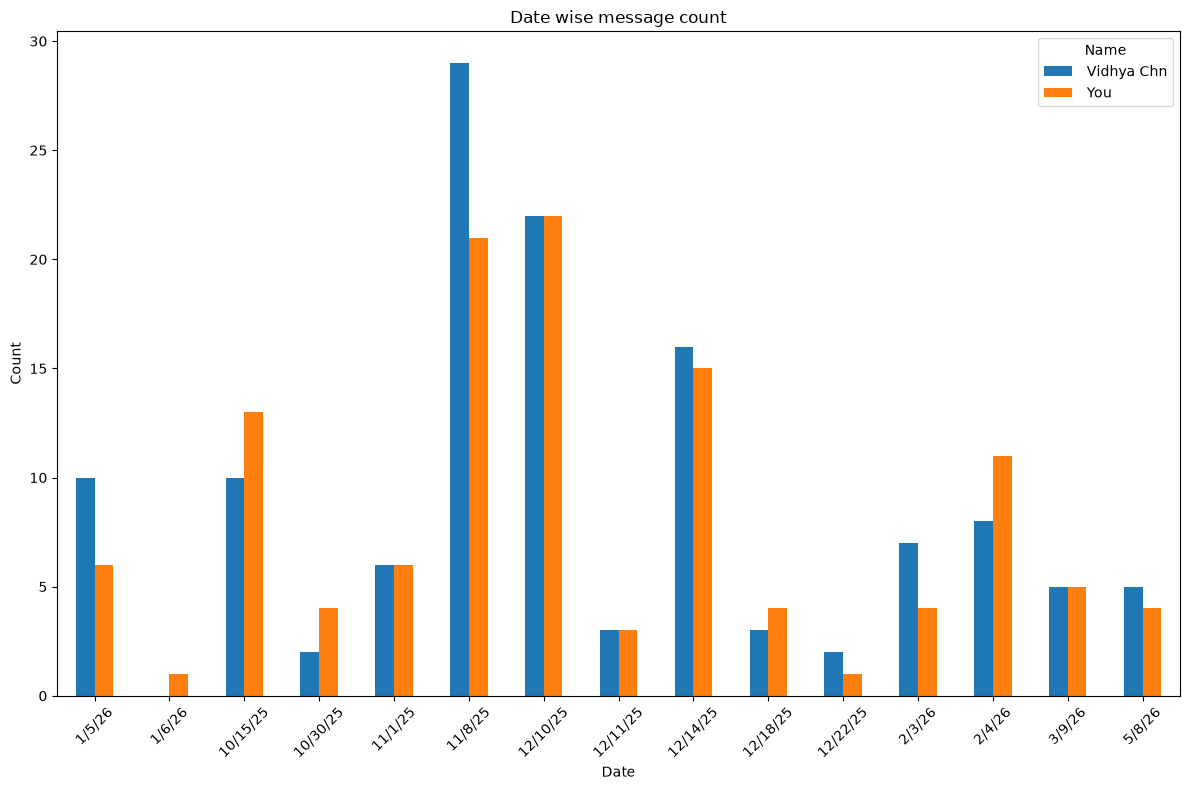

In [97]:
import matplotlib.pyplot as plt

daily_messages = df.groupby(['Date', 'Name']).size().unstack(fill_value=0)

daily_messages.plot(kind='bar', figsize=(12, 8))

plt.xlabel('Date')
plt.ylabel('Count')
plt.title('Date wise message count')
plt.xticks(rotation=45)
plt.legend(title='Name')

plt.tight_layout()
plt.show()

In [ ]:
##Sentimental Analysis

In [98]:
from nltk.sentiment.vader import SentimentIntensityAnalyzer
dataset=df

In [99]:
dataset.dropna(inplace=True)

In [100]:
sid=SentimentIntensityAnalyzer()
senti=sid.polarity_scores(df['Message'][4])
senti

{'neg': 0.0, 'neu': 0.769, 'pos': 0.231, 'compound': 0.4019}

In [101]:
def sentimentalAnalysis(data,columnname):

    #downloading vader_Lexicon for the process
    import matplotlib.pyplot as plt
    import seaborn as sns
    from nltk.sentiment.vader import SentimentIntensityAnalyzer
    
    sid=SentimentIntensityAnalyzer()
    data.dropna(inplace=True)
    
    #senti=sid.polarity_scores(df['Message'][4])
    data['Scores']=data[columnname].apply(lambda commenttext: sid.polarity_scores(commenttext))
    data['Compound']=data['Scores'].apply(lambda score_dict: score_dict['compound'])
    data['Negative']=data['Scores'].apply(lambda score_dict: score_dict['neg'])
    data['Positive']=data['Scores'].apply(lambda score_dict: score_dict['pos'])
    data['Neutral']=data['Scores'].apply(lambda score_dict: score_dict['neu'])

    data['comp_score']= data['Compound'].apply(lambda c: 'pos' if c >=0 else 'neg')
    plt.clf()

    posneg=pd.DataFrame(data['comp_score'].value_counts())
    return posneg,data

        

In [102]:
pos,data_senti=sentimentalAnalysis(dataset,columnname='Message')

<Figure size 640x480 with 0 Axes>

In [103]:
data_senti

,Date,Time,Name,Message,label,Scores,Compound,Negative,Positive,Neutral,comp_score
1,10/15/25,12:24:55 PM,You,Vithi,Non-Flirt,"{'neg': 0.0, 'neu': 1.0, 'pos': 0.0, 'compound...",0.0000,0.000,0.000,1.000,pos
2,10/15/25,12:25:21 PM,You,When is your next check-up?,Flirt,"{'neg': 0.0, 'neu': 1.0, 'pos': 0.0, 'compound...",0.0000,0.000,0.000,1.000,pos
3,10/15/25,12:37:00 PM,Vidhya Chn,Coming Saturday da..but anna is going to nat...,Flirt,"{'neg': 0.131, 'neu': 0.869, 'pos': 0.0, 'comp...",-0.2411,0.131,0.000,0.869,neg
4,10/15/25,12:37:52 PM,You,Oh . You need help to take you to the hospital?,Flirt,"{'neg': 0.0, 'neu': 0.769, 'pos': 0.231, 'comp...",0.4019,0.000,0.231,0.769,pos
5,10/15/25,12:38:25 PM,You,Magesh can come da,Flirt,"{'neg': 0.0, 'neu': 1.0, 'pos': 0.0, 'compound...",0.0000,0.000,0.000,1.000,pos
...,...,...,...,...,...,...,...,...,...,...,...
244,5/8/26,7:30:11 PM,Vidhya Chn,How is ur health now,Flirt,"{'neg': 0.0, 'neu': 1.0, 'pos': 0.0, 'compound...",0.0000,0.000,0.000,1.000,pos
245,5/8/26,7:30:22 PM,Vidhya Chn,How is both princess,Flirt,"{'neg': 0.0, 'neu': 1.0, 'pos': 0.0, 'compound...",0.0000,0.000,0.000,1.000,pos
246,5/8/26,10:50:51 PM,You,We are doing good ma,Flirt,"{'neg': 0.0, 'neu': 0.58, 'pos': 0.42, 'compou...",0.4404,0.000,0.420,0.580,pos
247,5/8/26,10:51:08 PM,You,Hope you are Walking normally,Flirt,"{'neg': 0.0, 'neu': 0.58, 'pos': 0.42, 'compou...",0.4404,0.000,0.420,0.580,pos


In [104]:
pos

,count
comp_score,
pos,230
neg,18


In [ ]:
######TOPIC MODELLING#####

In [105]:
vectorizer = CountVectorizer(stop_words='english') 
dtm = vectorizer.fit_transform(df['Message'])

In [106]:
from sklearn.decomposition import LatentDirichletAllocation
# Initialize and fit Topic Model
lda = LatentDirichletAllocation(n_components=5, random_state=42)
lda.fit(dtm)

,"n_components n_components: int, default=10Number of topics... versionchanged:: 0.19 ``n_topics`` was renamed to ``n_components``",5
,"random_state random_state: int, RandomState instance or None, default=NonePass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"doc_topic_prior doc_topic_prior: float, default=NonePrior of document topic distribution `theta`. If the value is None,defaults to `1 / n_components`.In [1]_, this is called `alpha`.",None
,"topic_word_prior topic_word_prior: float, default=NonePrior of topic word distribution `beta`. If the value is None, defaultsto `1 / n_components`.In [1]_, this is called `eta`.",None
,"learning_method learning_method: {'batch', 'online'}, default='batch'Method used to update `_component`. Only used in :meth:`fit` method.In general, if the data size is large, the online update will be muchfaster than the batch update.Valid options:- 'batch': Batch variational Bayes method. Use all training data in each EM update. Old `components_` will be overwritten in each iteration.- 'online': Online variational Bayes method. In each EM update, use mini-batch of training data to update the ``components_`` variable incrementally. The learning rate is controlled by the ``learning_decay`` and the ``learning_offset`` parameters... versionchanged:: 0.20 The default learning method is now ``""batch""``.",'batch'
,"learning_decay learning_decay: float, default=0.7It is a parameter that control learning rate in the online learningmethod. The value should be set between (0.5, 1.0] to guaranteeasymptotic convergence. When the value is 0.0 and batch_size is``n_samples``, the update method is same as batch learning. In theliterature, this is called kappa.",0.7
,"learning_offset learning_offset: float, default=10.0A (positive) parameter that downweights early iterations in onlinelearning. It should be greater than 1.0. In the literature, this iscalled tau_0.",10.0
,"max_iter max_iter: int, default=10The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the :meth:`fit` method, and not the:meth:`partial_fit` method.",10
,"batch_size batch_size: int, default=128Number of documents to use in each EM iteration. Only used in onlinelearning.",128
,"evaluate_every evaluate_every: int, default=-1How often to evaluate perplexity. Only used in `fit` method.set it to 0 or negative number to not evaluate perplexity intraining at all. Evaluating perplexity can help you check convergencein training process, but it will also increase total training time.Evaluating perplexity in every iteration might increase training timeup to two-fold.",-1
,"total_samples total_samples: int, default=1e6Total number of documents. Only used in the :meth:`partial_fit` method.",1000000.0


In [107]:
# Extract the explicit vocabulary names mapped to each feature index
# Note: This step completely breaks if you use HashingVectorizer instead!
feature_names = vectorizer.get_feature_names_out()
feature_names

array(['10', '13', '5hours', 'aama', 'able', 'ada', 'adapt',
       'adichirukum', 'adighama', 'adu', 'aduku', 'afternoon', 'aga',
       'ah', 'aicho', 'aidanum', 'aiduchu', 'aiduthu', 'aiyo', 'album',
       'ama', 'amaa', 'anna', 'antibiotics', 'apo', 'appo', 'arambi',
       'ask', 'asked', 'auto', 'avaluku', 'avaruku', 'awesome', 'bad',
       'bear', 'best', 'better', 'bigger', 'bit', 'body', 'bore',
       'bought', 'bro', 'buy', 'cancelling', 'care', 'careful', 'cha',
       'change', 'check', 'chitti', 'chk', 'color', 'come', 'coming',
       'commuting', 'completely', 'cooking', 'couldn', 'da', 'daaa',
       'daflirt', 'dai', 'dav', 'day', 'days', 'didn', 'dinner', 'doing',
       'don', 'dr', 'dress', 'drips', 'edachum', 'edu', 'edukuthu',
       'eduthanga', 'eduthoko', 'eduthuko', 'enjoy', 'enna', 'epdi',
       'evening', 'excited', 'exercises', 'feeling', 'fever', 'fine',
       'food', 'forget', 'form', 'forwarded', 'free', 'freely', 'getting',
       'gifts', 'girls',

In [108]:
for index,topic in enumerate(lda.components_):
    results=([feature_names[i] for i in topic.argsort()[-10:]])
    print(results)

['couldn', 'help', 'let', 'know', 'better', 'da', 'week', 'yeah', 'ma', 'sure']
['dinner', 'today', 'ma', 'forwarded', 'ha', 'hi', 'ok', 'omitted', 'image', 'da']
['hospital', 'ask', 'kutties', 'time', 'super', 'thought', 'hmm', 'walking', 'ma', 'good']
['going', 'support', 'walk', 'plan', 'care', 'meenu', 'yes', 'oh', 'vithi', 'da']
['walk', 'ohh', 'konjam', 'walking', 'fever', 'started', 'care', 'good', 'ok', 'da']


In [109]:
topic_results=lda.transform(dtm)
df['Topic']=topic_results.argmax(axis=1)

In [110]:
df['Topic'].value_counts()

Topic
4    81
1    50
0    45
3    41
2    31
Name: count, dtype: int64

In [111]:
df

,Date,Time,Name,Message,label,Scores,Compound,Negative,Positive,Neutral,comp_score,Topic
1,10/15/25,12:24:55 PM,You,Vithi,Non-Flirt,"{'neg': 0.0, 'neu': 1.0, 'pos': 0.0, 'compound...",0.0000,0.000,0.000,1.000,pos,3
2,10/15/25,12:25:21 PM,You,When is your next check-up?,Flirt,"{'neg': 0.0, 'neu': 1.0, 'pos': 0.0, 'compound...",0.0000,0.000,0.000,1.000,pos,4
3,10/15/25,12:37:00 PM,Vidhya Chn,Coming Saturday da..but anna is going to nat...,Flirt,"{'neg': 0.131, 'neu': 0.869, 'pos': 0.0, 'comp...",-0.2411,0.131,0.000,0.869,neg,3
4,10/15/25,12:37:52 PM,You,Oh . You need help to take you to the hospital?,Flirt,"{'neg': 0.0, 'neu': 0.769, 'pos': 0.231, 'comp...",0.4019,0.000,0.231,0.769,pos,3
5,10/15/25,12:38:25 PM,You,Magesh can come da,Flirt,"{'neg': 0.0, 'neu': 1.0, 'pos': 0.0, 'compound...",0.0000,0.000,0.000,1.000,pos,1
...,...,...,...,...,...,...,...,...,...,...,...,...
244,5/8/26,7:30:11 PM,Vidhya Chn,How is ur health now,Flirt,"{'neg': 0.0, 'neu': 1.0, 'pos': 0.0, 'compound...",0.0000,0.000,0.000,1.000,pos,4
245,5/8/26,7:30:22 PM,Vidhya Chn,How is both princess,Flirt,"{'neg': 0.0, 'neu': 1.0, 'pos': 0.0, 'compound...",0.0000,0.000,0.000,1.000,pos,1
246,5/8/26,10:50:51 PM,You,We are doing good ma,Flirt,"{'neg': 0.0, 'neu': 0.58, 'pos': 0.42, 'compou...",0.4404,0.000,0.420,0.580,pos,2
247,5/8/26,10:51:08 PM,You,Hope you are Walking normally,Flirt,"{'neg': 0.0, 'neu': 0.58, 'pos': 0.42, 'compou...",0.4404,0.000,0.420,0.580,pos,2
